In [4]:
from pathlib import Path
import os

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

os.chdir(project_root)

print("Current working directory:")
print(os.getcwd())

Current working directory:
/home/anshul/crop-disease-detection


In [5]:
import json
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10
NUM_CLASSES = 38

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
train_data = tf.keras.utils.image_dataset_from_directory(
    "data/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

valid_data = tf.keras.utils.image_dataset_from_directory(
    "data/valid",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_data.class_names

AUTOTUNE = tf.data.AUTOTUNE

def normalize(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

train_data = train_data.map(
    normalize,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

valid_data = valid_data.map(
    normalize,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("Number of classes:", len(class_names))
print("Datasets are ready.")

Found 70295 files belonging to 38 classes.


I0000 00:00:1795615411.995494   30411 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4135 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 17572 files belonging to 38 classes.
Number of classes: 38
Datasets are ready.


In [7]:
model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 463,974 (1.77 MB)

 Trainable params: 463,974 (1.77 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath="models/best_baseline_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_callback = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    verbose=1
)

callbacks = [
    checkpoint_callback,
    early_stopping_callback,
    reduce_lr_callback
]

print("Callbacks are ready.")

Callbacks are ready.


In [9]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Built with CUDA:", tf.test.is_built_with_cuda())

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Built with CUDA: True


In [10]:
import tensorflow as tf
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

history = model.fit(
    train_data,
    validation_data=valid_data,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/10


/home/anshul/crop-disease-detection/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795615415.936950   30683 service.cc:153] XLA service 0x7d080c149210 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795615415.936977   30683 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795615416.120235   30683 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795615416.463173   30683 cuda_dnn.cc:461] Loaded cuDNN version 92801
I0000 00:00:1795615416.506889   30683 dot

   2/2197 ━━━━━━━━━━━━━━━━━━━━ 2:29 68ms/step - accuracy: 0.0469 - loss: 3.6391  

I0000 00:00:1795615429.106246   30683 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2196/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.4497 - loss: 1.8565

I0000 00:00:1795615564.333883   30686 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2375__.50
I0000 00:00:1795615568.149173   30686 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.4497 - loss: 1.8564

I0000 00:00:1795615583.510617   30686 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.



Epoch 1: val_accuracy improved from None to 0.77157, saving model to models/best_baseline_model.keras

Epoch 1: finished saving model to models/best_baseline_model.keras
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 188s 79ms/step - accuracy: 0.4497 - loss: 1.8564 - val_accuracy: 0.7716 - val_loss: 0.7474 - learning_rate: 0.0010
Epoch 2/10
2196/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.7805 - loss: 0.6891
Epoch 2: val_accuracy improved from 0.77157 to 0.87122, saving model to models/best_baseline_model.keras

Epoch 2: finished saving model to models/best_baseline_model.keras
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 144s 65ms/step - accuracy: 0.7805 - loss: 0.6890 - val_accuracy: 0.8712 - val_loss: 0.4045 - learning_rate: 0.0010
Epoch 3/10
2196/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.8577 - loss: 0.4450
Epoch 3: val_accuracy improved from 0.87122 to 0.92124, saving model to models/best_baseline_model.keras

Epoch 3: finished saving model to models/best_baseline_model.keras
2197/2197 ━━━

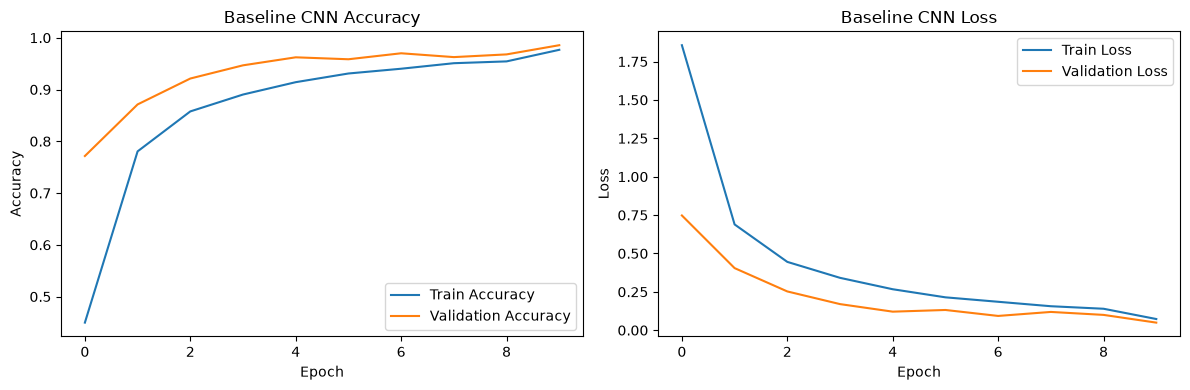

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Baseline CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Baseline CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
import json

baseline_results = {
    "best_val_accuracy": max(history.history["val_accuracy"]),
    "best_val_loss": min(history.history["val_loss"]),
    "epochs_completed": len(history.history["loss"])
}

with open("results/baseline_results.json", "w") as f:
    json.dump(baseline_results, f, indent=4)

model.save("models/baseline_cnn.keras")

print("Baseline model saved.")
print(baseline_results)

Baseline model saved.
{'best_val_accuracy': 0.985602080821991, 'best_val_loss': 0.049399323761463165, 'epochs_completed': 10}
